# Notebook 05: Classical and QSVM comparison
This notebook audits and interprets completed Stage 3 and Stage 4 experiments. It does not train models, adjust parameters, or run new quantum experiments. Small committed evidence snapshots allow it to run without downloading the full feature dataset.

Stage 3 uses 2,500 development and 1,000 evaluation rows with 16 inputs. Stage 4 uses 280 final development and 100 evaluation rows with 2 or 4 PCA components. Only models within Stage 4 share identical observations and representations; a cross-stage ranking would confound changes in sample size and preprocessing.

### Cell 1: Load comparison evidence

Audit and interpret the original binary evidence without retuning models.

In [1]:
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,precision_score,
    recall_score,f1_score,roc_auc_score,average_precision_score,roc_curve,precision_recall_curve)
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
EVIDENCE=ROOT/'reports/stage5/evidence'
OUT=ROOT/'results/stage5'; OUT.mkdir(parents=True,exist_ok=True)
manifest=json.loads((EVIDENCE/'manifest.json').read_text())
for name,item in manifest.items():
    assert hashlib.sha256((EVIDENCE/name).read_bytes()).hexdigest()==item['sha256'], name
m3=pd.read_csv(EVIDENCE/'stage3_metrics.csv')
m4=pd.read_csv(EVIDENCE/'stage4_metrics.csv')
pred=pd.read_csv(EVIDENCE/'stage4_predictions.csv',parse_dates=['Date'])
s3=pd.read_csv(EVIDENCE/'stage3_splits.csv')
s4=pd.read_csv(EVIDENCE/'stage4_splits.csv')
pca=pd.read_csv(EVIDENCE/'stage4_pca_summary.csv')
diag=pd.DataFrame(json.loads((EVIDENCE/'stage4_kernel_diagnostics.json').read_text()))
meta3=json.loads((EVIDENCE/'stage3_metadata.json').read_text())
meta4=json.loads((EVIDENCE/'stage4_metadata.json').read_text())
assert meta3['input_sha256']==meta4['input_sha256']
assert not pred.duplicated(['Ticker','Date']).any()
assert len(pred)==int(s4.loc[s4.split=='evaluation','rows'].iloc[0])
assert pred.target_up.isin([0,1]).all() and pred.target_up.nunique()==2
print('Evidence hashes, common source hashes, and observation keys verified.')

Evidence hashes, common source hashes, and observation keys verified.


## Recompute reported metrics from saved predictions
Every Stage 4 model must have predictions and scores for the same 100 observations. Verify accuracy, balanced accuracy, precision, recall, F1, ROC-AUC and average precision, rather than trusting a copied metrics table.

### Cell 2: Validate source snapshots

Audit and interpret the original binary evidence without retuning models.

In [2]:
audit=[]
for _,row in m4.iterrows():
    key=f'{row.model}_{row.dimension}d'
    y=pred.target_up; labels=pred[key+'_prediction']; scores=pred[key+'_score']
    assert labels.isin([0,1]).all() and np.isfinite(scores).all()
    values=dict(accuracy=accuracy_score(y,labels),balanced_accuracy=balanced_accuracy_score(y,labels),
        precision=precision_score(y,labels,zero_division=0),recall=recall_score(y,labels,zero_division=0),
        f1=f1_score(y,labels,zero_division=0),roc_auc=roc_auc_score(y,scores),average_precision=average_precision_score(y,scores))
    for metric,value in values.items(): assert np.isclose(value,row[metric],atol=1e-12), (key,metric)
    audit.append(dict(dimension=row.dimension,model=row.model,**values))
assert len(audit)==10
audited=pd.DataFrame(audit)
assert np.array_equal(pred.dummy_2d_prediction,pred.dummy_4d_prediction)
display(audited.round(4))
print('All 70 metric values reproduce from saved predictions.')

,dimension,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
0,2,dummy,0.68,0.5000,0.6800,1.0000,0.8095,0.5000,0.6800
1,2,linear,0.63,0.5790,0.7313,0.7206,0.7259,0.5979,0.7479
2,2,rbf,0.54,0.5377,0.7115,0.5441,0.6167,0.5942,0.7478
3,2,polynomial,0.58,0.5836,0.7500,0.5735,0.6500,0.5786,0.7185
4,2,qsvm,0.59,0.5165,0.6901,0.7206,0.7050,0.5101,0.6727
5,4,dummy,0.68,0.5000,0.6800,1.0000,0.8095,0.5000,0.6800
6,4,linear,0.49,0.5588,0.7576,0.3676,0.4950,0.5538,0.7301
7,4,rbf,0.32,0.5000,0.0000,0.0000,0.0000,0.5386,0.7222
8,4,polynomial,0.40,0.4844,0.6538,0.2500,0.3617,0.5528,0.7083
9,4,qsvm,0.50,0.5414,0.7250,0.4265,0.5370,0.5358,0.6819


All 70 metric values reproduce from saved predictions.


## Compare against baselines without picking a test-set winner
For each dimension, show QSVM differences against every classical SVM. Separately identify the classical comparator using its validation score only. This analysis does not reselect models using evaluation outcomes. Percentage-point differences are descriptive, not statistical significance.

### Cell 3: Audit saved predictions

Audit and interpret the original binary evidence without retuning models.

In [3]:
paired=[]; selected=[]
for d in [2,4]:
    group=m4.loc[m4.dimension==d].set_index('model')
    q=group.loc['qsvm']
    for name in ['linear','rbf','polynomial']:
        c=group.loc[name]
        paired.append(dict(dimension=d,classical_model=name,
            balanced_accuracy_delta_pp=100*(q.balanced_accuracy-c.balanced_accuracy),
            roc_auc_delta= q.roc_auc-c.roc_auc))
    name=group.loc[['linear','rbf','polynomial'],'validation_balanced_accuracy'].idxmax()
    selected.append(dict(dimension=d,validation_selected_classical=name,
        classical_balanced_accuracy=group.loc[name,'balanced_accuracy'],
        qsvm_balanced_accuracy=q.balanced_accuracy,
        qsvm_minus_classical_pp=100*(q.balanced_accuracy-group.loc[name,'balanced_accuracy'])))
paired=pd.DataFrame(paired); selected=pd.DataFrame(selected)
display(paired.round(4)); display(selected.round(4))
class_balance=pred.target_up.value_counts().reindex([0,1]).rename('rows').to_frame()
class_balance['fraction']=class_balance.rows/len(pred)
display(class_balance)

,dimension,classical_model,balanced_accuracy_delta_pp,roc_auc_delta
0,2,linear,-6.2500,-0.0878
1,2,rbf,-2.1140,-0.0841
2,2,polynomial,-6.7096,-0.0685
3,4,linear,-1.7463,-0.0179
4,4,rbf,4.1360,-0.0028
5,4,polynomial,5.6985,-0.0170


,dimension,validation_selected_classical,classical_balanced_accuracy,qsvm_balanced_accuracy,qsvm_minus_classical_pp
0,2,rbf,0.5377,0.5165,-2.1140
1,4,linear,0.5588,0.5414,-1.7463


,rows,fraction
target_up,,
0,32,0.32
1,68,0.68


## Account for quantum kernel cost
The Stage 4 SVC fit timer excludes explicit quantum kernel construction. For a like-for-like final execution accounting, add preprocessing, model fitting, prediction, and (for QSVM) both kernel builds. Classical kernel calculations already occur inside SVC fit/predict.

This is a sum of measured components, not an independently timed entire workflow. It excludes data loading, hyperparameter search and verification. Shared preprocessing is allocated once per hypothetical model run. Tiny single-run timings are machine-specific; no hardware speedup conclusion is supported.

### Cell 4: Compare matched models

Audit and interpret the original binary evidence without retuning models.

In [4]:
runtime=m4[['dimension','model','preprocessing_seconds','fit_seconds','predict_seconds','train_kernel_seconds','test_kernel_seconds']].copy()
timing_columns=['preprocessing_seconds','fit_seconds','predict_seconds','train_kernel_seconds','test_kernel_seconds']
assert (runtime[timing_columns]>=0).all().all()
runtime['accounted_final_seconds']=runtime[timing_columns].sum(axis=1)
runtime['kernel_fraction']=(runtime.train_kernel_seconds+runtime.test_kernel_seconds)/runtime.accounted_final_seconds
display(runtime.round(6))
resources=diag.loc[diag.phase=='final',['dimension','train_shape','cross_shape','kernel_array_bytes','circuit_depth','two_qubit_gates']].copy()
resources['kernel_arrays_MiB']=resources.kernel_array_bytes/1024**2
display(resources)
display(pca)

,dimension,model,preprocessing_seconds,fit_seconds,predict_seconds,train_kernel_seconds,test_kernel_seconds,accounted_final_seconds,kernel_fraction
0,2,dummy,0.006339,0.000509,0.000074,0.000000,0.000000,0.006923,0.000000
1,2,linear,0.006339,0.002665,0.000909,0.000000,0.000000,0.009914,0.000000
2,2,rbf,0.006339,0.002790,0.002981,0.000000,0.000000,0.012111,0.000000
3,2,polynomial,0.006339,0.004564,0.000841,0.000000,0.000000,0.011744,0.000000
4,2,qsvm,0.006339,0.002799,0.000528,0.428861,0.221939,0.660467,0.985364
5,4,dummy,0.006895,0.000457,0.000073,0.000000,0.000000,0.007425,0.000000
6,4,linear,0.006895,0.002636,0.000907,0.000000,0.000000,0.010439,0.000000
7,4,rbf,0.006895,0.002884,0.003090,0.000000,0.000000,0.012869,0.000000
8,4,polynomial,0.006895,0.002663,0.001035,0.000000,0.000000,0.010592,0.000000
9,4,qsvm,0.006895,0.002182,0.000556,0.505955,0.313004,0.828592,0.988374


,dimension,train_shape,cross_shape,kernel_array_bytes,circuit_depth,two_qubit_gates,kernel_arrays_MiB
2,2,"[280, 280]","[100, 280]",851200,5,2,0.811768
3,4,"[280, 280]","[100, 280]",851200,11,6,0.811768


,dimension,explained_variance,test_clipped_fraction
0,2,0.659586,0.0000
1,4,0.838643,0.0025


## Diagnostic figures
The precision-recall baseline is the observed positive fraction (68%), not 50%. The 20 sampled market dates contain correlated stocks, so the 100 rows should not be treated as 100 independent trials. Per-ticker metrics are only diagnostics on 20 observations each.

### Cell 5: Account for computational costs

Audit and interpret the original binary evidence without retuning models.

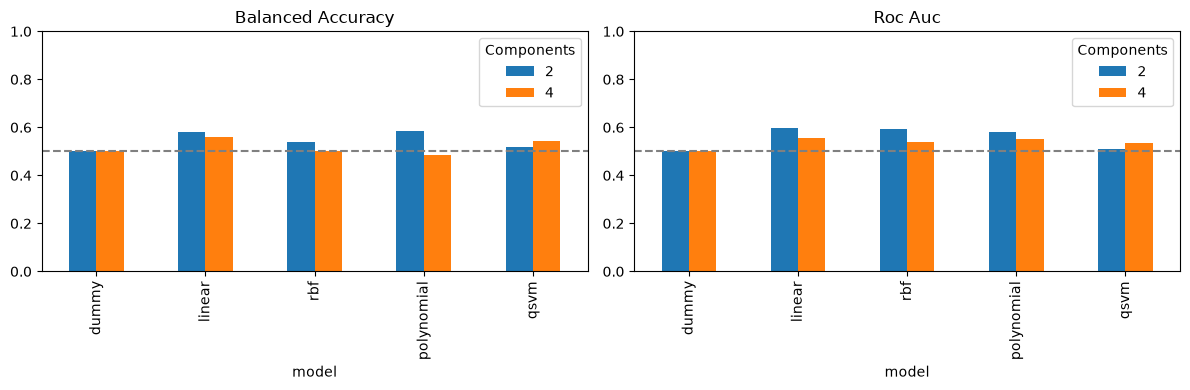

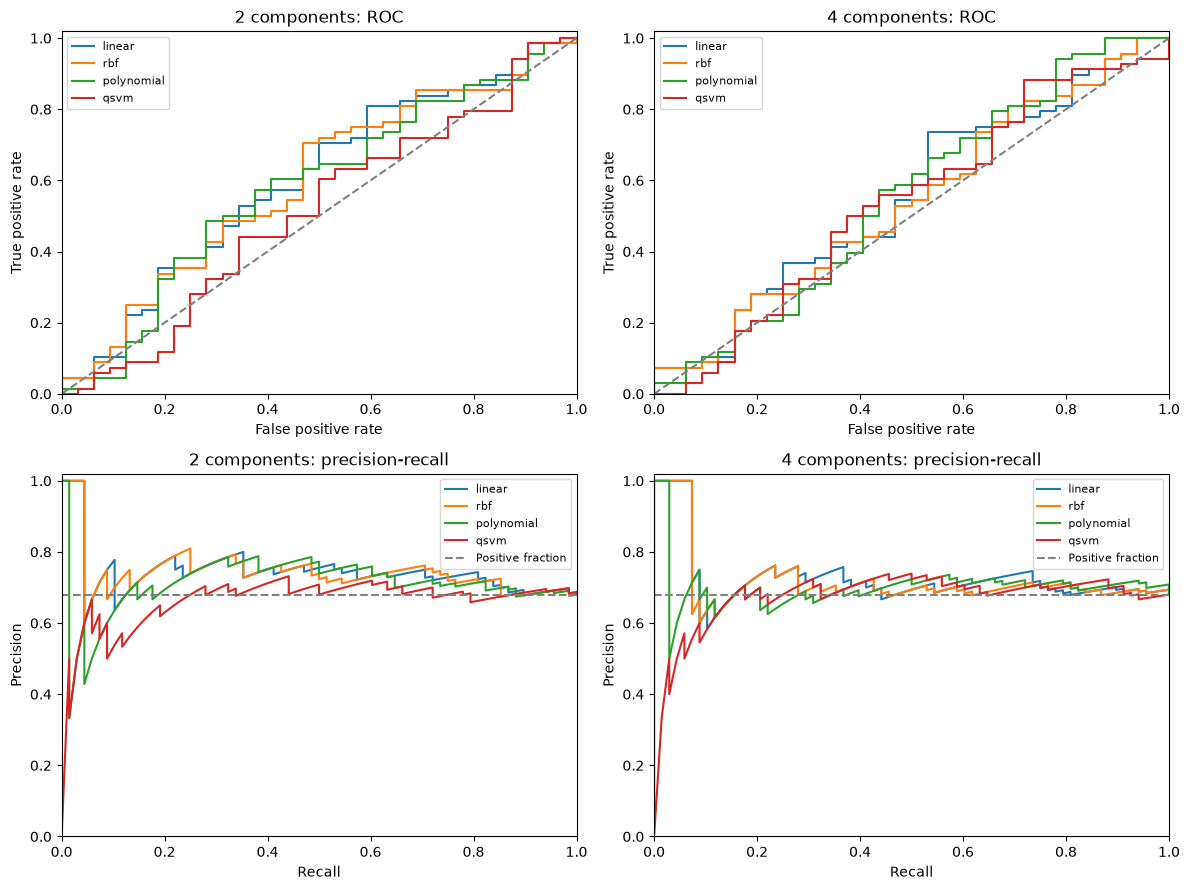

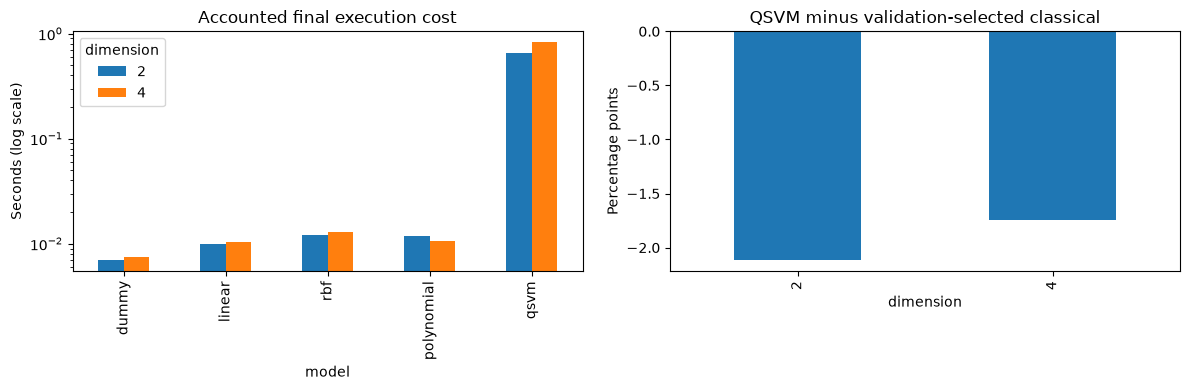

,ticker,dimension,model,rows,balanced_accuracy
0,AAPL,2,qsvm,20,0.4667
1,AAPL,2,rbf,20,0.4333
2,AAPL,4,qsvm,20,0.4667
3,AAPL,4,linear,20,0.5000
4,JNJ,2,qsvm,20,0.3958
5,JNJ,2,rbf,20,0.5833
6,JNJ,4,qsvm,20,0.5417
7,JNJ,4,linear,20,0.6458
8,JPM,2,qsvm,20,0.5490
9,JPM,2,rbf,20,0.5686


In [5]:
order=['dummy','linear','rbf','polynomial','qsvm']
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,['balanced_accuracy','roc_auc']):
    m4.pivot(index='model',columns='dimension',values=metric).reindex(order).plot.bar(ax=ax)
    ax.axhline(0.5,color='gray',linestyle='--'); ax.set_ylim(0,1)
    ax.set_title(metric.replace('_',' ').title()); ax.legend(title='Components')
fig.tight_layout(); fig.savefig(OUT/'matched_metrics.png',dpi=150); plt.show()
fig,axes=plt.subplots(2,2,figsize=(12,9))
for col,d in enumerate([2,4]):
    for name in ['linear','rbf','polynomial','qsvm']:
        score=pred[f'{name}_{d}d_score']
        fpr,tpr,_=roc_curve(pred.target_up,score)
        precision,recall,_=precision_recall_curve(pred.target_up,score)
        axes[0,col].plot(fpr,tpr,label=name); axes[1,col].plot(recall,precision,label=name)
    axes[0,col].plot([0,1],[0,1],'--',color='gray'); axes[0,col].set_title(f'{d} components: ROC')
    axes[0,col].set_xlabel('False positive rate'); axes[0,col].set_ylabel('True positive rate')
    axes[1,col].axhline(pred.target_up.mean(),color='gray',linestyle='--',label='Positive fraction')
    axes[1,col].set_title(f'{d} components: precision-recall')
    axes[1,col].set_xlabel('Recall'); axes[1,col].set_ylabel('Precision')
for ax in axes.ravel(): ax.set_xlim(0,1); ax.set_ylim(0,1.02); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT/'roc_pr_curves.png',dpi=150); plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
runtime.pivot(index='model',columns='dimension',values='accounted_final_seconds').reindex(order).plot.bar(ax=axes[0],logy=True)
axes[0].set_ylabel('Seconds (log scale)'); axes[0].set_title('Accounted final execution cost')
selected.plot.bar(x='dimension',y='qsvm_minus_classical_pp',ax=axes[1],legend=False)
axes[1].axhline(0,color='gray'); axes[1].set_ylabel('Percentage points'); axes[1].set_title('QSVM minus validation-selected classical')
fig.tight_layout(); fig.savefig(OUT/'cost_and_difference.png',dpi=150); plt.show()
per_ticker=[]
for ticker,frame in pred.groupby('Ticker'):
    assert frame.target_up.nunique()==2
    for d in [2,4]:
        name=selected.loc[selected.dimension==d,'validation_selected_classical'].iloc[0]
        for model in ['qsvm',name]:
            per_ticker.append(dict(ticker=ticker,dimension=d,model=model,rows=len(frame),
                balanced_accuracy=balanced_accuracy_score(frame.target_up,frame[f'{model}_{d}d_prediction'])))
per_ticker=pd.DataFrame(per_ticker)
display(per_ticker.round(4))

## Interpretation and the remaining experiments
The QSVMs exceed the dummy's balanced accuracy in this small evaluation, but neither exceeds its validation-selected classical comparator. Raw accuracy alone is misleading here because 68% of labels are UP. All measured results are descriptive and based on a previously examined period.

The comparison protocol is now implemented and audited. The agreed approximate 70% implementation milestone is reached; this is not 70% of scientific validation or a guarantee of remaining effort.

Remaining stages: (1) prespecified sample/dimension scaling, circuit/shot/noise experiments, and optional separately authorized hardware use; (2) time-aware uncertainty estimates, robustness, source-data review, and the final report. Future protocol choices should not be optimized using these test outcomes. No statistical significance or quantum advantage is established.

### Cell 6: Save comparison findings

Audit and interpret the original binary evidence without retuning models.

In [6]:
audited.to_csv(OUT/'audited_metrics.csv',index=False)
paired.to_csv(OUT/'paired_differences.csv',index=False)
selected.to_csv(OUT/'validation_selected_comparison.csv',index=False)
runtime.to_csv(OUT/'accounted_runtime.csv',index=False)
resources.to_csv(OUT/'kernel_resources.csv',index=False)
per_ticker.to_csv(OUT/'per_ticker_diagnostics.csv',index=False)
summary=dict(verified_metric_values=70,evaluation_rows=len(pred),evaluation_dates=pred.Date.nunique(),
    models=order,dimensions=[2,4],positive_fraction=float(pred.target_up.mean()),
    limitations=['Small correlated sample','Previously examined evaluation period','Survivorship bias',
    'Unverified price adjustments','Single-run simulator timing','No significance analysis'],
    source_manifest=manifest)
(OUT/'analysis_metadata.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Stage 5 comparison analysis completed. No new models trained or selected on evaluation outcomes.')

Stage 5 comparison analysis completed. No new models trained or selected on evaluation outcomes.


### Audit the binary and three-class extension

Recompute metrics from saved predictions and freeze separate reproducibility evidence.

In [7]:
import runpy
from pathlib import Path
EXT_ROOT = Path.cwd()
if EXT_ROOT.name == 'notebooks': EXT_ROOT = EXT_ROOT.parent
extension = runpy.run_path(str(EXT_ROOT / 'experiments/multiclass_extension.py'))
extension_all_metrics, extension_comparison = extension['audit'](EXT_ROOT)
display(extension_comparison)
print('Recomputed five metrics for each of', len(extension_all_metrics), 'model/task configurations.')

,task,dimension,classical_model,classical_balanced_accuracy,qsvm_balanced_accuracy,difference_pp
0,binary,2,rbf,0.499317,0.484888,-1.442839
1,binary,4,polynomial,0.513420,0.477259,-3.616045
2,three_class,2,polynomial,0.368209,0.351601,-1.660784
3,three_class,4,linear,0.342438,0.304258,-3.817963


Recomputed five metrics for each of 28 model/task configurations.


### Visualize each task separately

Compare matched models and inspect the binary and three-class QSVM confusion matrices.

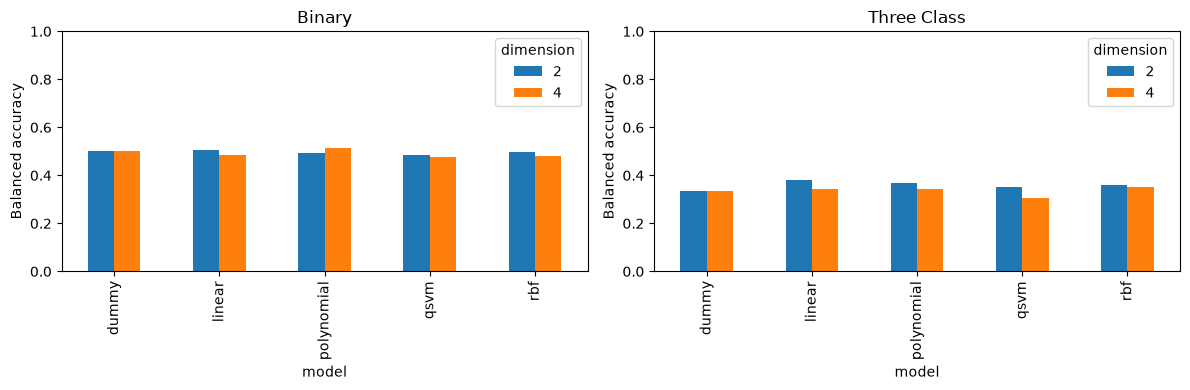

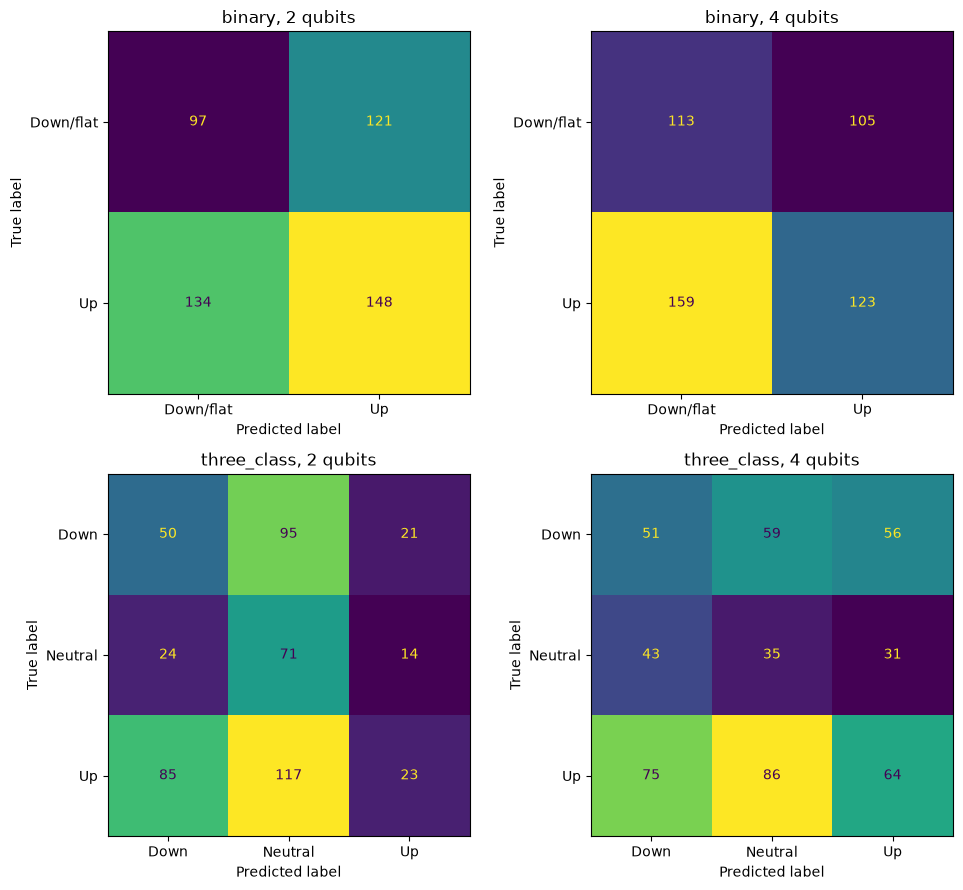

In [8]:
extension['figures'](EXT_ROOT)

## Updated project status

The original binary comparison is complete. The extension above reports binary plus three-class results only after successful execution. Five-class and noise simulation remain later extensions. Scaling/circuit studies and time-aware statistical validation remain planned. The previous approximately 70% milestone refers to the original scope, not the expanded project. No quantum advantage or profitability is established.